In [147]:
!pip install pdfplumber pandas

In [149]:
import pdfplumber

with pdfplumber.open("combined2025_RollCalls.pdf") as pdf:
        #Access pages and extract data
       for page in pdf.pages:
            text = page.extract_text()
            print(text)

MASSACHUSETTS HOUSE OF REPRESENTATIVES
H. 57 On adoption of amendment #6
Yea and Nay 02/06/2025 02:35 PM
No. 1 26 YEAS 126 NAYS 7 N/V
N Mr. Speaker N Galvin N McMurtry N Sylvia
N Arciero N Garballey N Mendes N Tarsky
N Arena-DeRosa N Garcia N Meschino N Turco
N Armini Y Garry N Michlewitz N Tyler *
N Arriaga N Gentile N Moakley N Ultrino
N Ashe N Giannino N Montaño N Uyterhoeven
N Ayers N Gómez N Moran F. N Vargas
N Badger N González N Moran J. N Vitolo
N Barber N Gordon N Moran M. N Walsh
N Barrett N Gregoire N Murphy N Wells
N Biele X Haggerty N Murray N Williams
X Blais N Hamilton N Nguyen N Worrell
N Cabral N Hawkins N O'Day N Zlotnik
N Cahill N Hendricks N Ouellette Y --Jones--
N Cataldo N Higgins N Owens Y Ferguson
N Chan N Hogan N Paulino Y Frost
N Ciccolo N Holmes N Peisch Y Berthiaume
N Connolly N Honan N Philips X Boldyga
N Consalvo N Hong N Plouffe Y Chaisson
N Cruz N Howard N Puppolo Y DeCoste
N Cusack N Hunt N Ramos, A. Y Gaskey
N Davis N Kassner N Ramos, O. Y Howitt
N Day

In [150]:
import pandas as pd
import re

def clean_name(name):
    "cleans through legislator namesfor any irregular formatting"
    return name.replace('*', '').strip()

def parse_2025(pdf_path):
    records = []

    with pdfplumber.open(pdf_path) as pdf:
        for page in pdf.pages:
            text = page.extract_text()
            if not text:
                continue  #skip empty pages

            lines = text.splitlines()
            bill_no = None
            amendment_no = None
            amendment_lines = []

            for line in lines:
                #Extract bill number
                if not bill_no:
                    bill_match = re.search(r'(H\.\s*\d+)', line)
                    if bill_match:
                        bill_no = bill_match.group(1)

                # Extract amendment number
                if not amendment_no:
                    amendment_match = re.search(r'amendment\s*(#\d+)', line, re.IGNORECASE)
                    if amendment_match:
                        amendment_no = amendment_match.group(1)

                #Skip headers/footers but keep vote lines
                if re.match(r'^(Yea and Nay|No\.|MASSACHUSETTS|^\s*$)', line):
                    continue

                #Detect when vote listings start (lines with Y/N/X/P)
                if re.search(r'\b(Y|N|X|P)\b', line):
                    amendment_lines.append(line)

            #tokenize all words in the amendment block
            tokens = []
            for line in amendment_lines:
                tokens.extend(line.strip().split())

            #Parsing through the votes
            i = 0
            while i < len(tokens):
                token = tokens[i]
                if token in ["Y", "N", "X", "P"]:
                    vote = token
                    i += 1
                    name_tokens = []
                    while i < len(tokens) and tokens[i] not in ["Y", "N", "X", "P"]: #check through voting categories 
                        name_tokens.append(tokens[i])
                        i += 1
                    name = clean_name(" ".join(name_tokens))
                    if name:
                        records.append({
                            'Bill No.': bill_no,
                            'Amendment No.': amendment_no,
                            'Legislator Name': name,
                            'Vote': vote
                        })
                else:
                    i += 1

    df = pd.DataFrame(records)
    return df

#Run parse
df_2025 = parse_2025("combined2025_RollCalls.pdf")
print(df_2025["Vote"].value_counts())
print("Total legislators parsed:", len(df_2025))

# save locally to csv file 
df_2025.to_csv("rollcall_2025.csv", index=False)


Vote
Y    10275
N     3859
X      484
P        3
Name: count, dtype: int64
Total legislators parsed: 14621


In [151]:
def normalize_bill(bill):
    if not bill:
        return ""
    return re.sub(r'\s+|\.', '', bill).upper()  # e.g., 'H. 57' -> 'H57'

def normalize_amendment(amend):
    if not amend:
        return ""
    amend = str(amend).strip()
    amend = amend.lstrip("#")
    return amend
#Function to extract specific bill and amendment roll call data 
def show_amendment_votes(df, bill_no=None, amendment_no=None): #takes bill and amendment no.
    subset = df.copy()

    #Normalize the input
    norm_bill = normalize_bill(bill_no)
    norm_amend = normalize_amendment(amendment_no)

    #Normalizing the columns for comparison
    df['Bill No. Norm'] = df['Bill No.'].apply(normalize_bill)
    df['Amendment No. Norm'] = df['Amendment No.'].apply(normalize_amendment)

    if bill_no:
        subset = df[df['Bill No. Norm'] == norm_bill]

    if amendment_no:
        subset = subset[subset['Amendment No. Norm'] == norm_amend]

    if subset.empty:
        print(f"No records found for Bill {bill_no} Amendment {amendment_no}")
        print("Available unique amendment numbers:", df['Amendment No.'].unique())
        return

    # Display data
    print(f"Roll call data for Bill {bill_no}, Amendment {amendment_no}\n")
    print(subset["Vote"].value_counts())
    print(f"\nTotal legislators parsed: {len(subset)}\n")

    return subset

In [152]:
show_amendment_votes(df_2025, 'H 57', 6)

Roll call data for Bill H 57, Amendment 6

Vote
N    126
Y     26
X      7
Name: count, dtype: int64

Total legislators parsed: 159



,Bill No.,Amendment No.,Legislator Name,Vote,Bill No. Norm,Amendment No. Norm
0,H. 57,#6,Mr. Speaker,N,H57,6
1,H. 57,#6,Galvin,N,H57,6
2,H. 57,#6,McMurtry,N,H57,6
3,H. 57,#6,Sylvia,N,H57,6
4,H. 57,#6,Arciero,N,H57,6
...,...,...,...,...,...,...
154,H. 57,#6,Sousa,N,H57,6
155,H. 57,#6,--Whipps--,X,H57,6
156,H. 57,#6,Gallagher,N,H57,6
157,H. 57,#6,McGonagle,N,H57,6


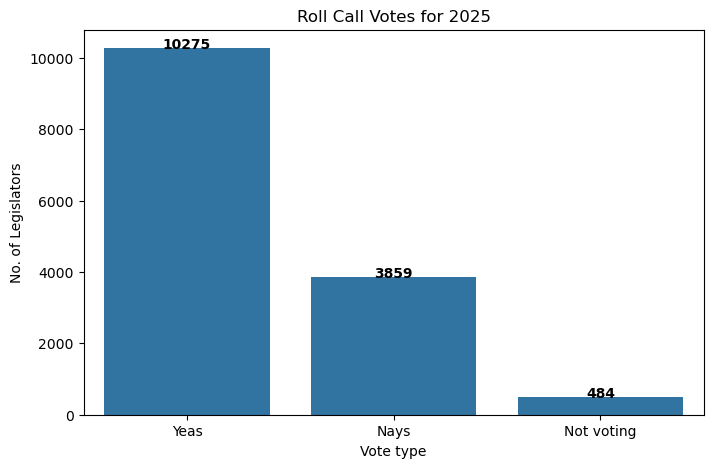

In [153]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
#This code displays a visualization for the 2025 year to date roll call data 
df = pd.read_csv("rollcall_2025.csv")
#cover all vote cases
vote_map = {"Y": "Yeas", "N": "Nays", "X": "Not voting"}
df["Vote Type"] = df["Vote"].map(vote_map)

# Count the number of votes per type
vote_counts = df["Vote Type"].value_counts().reindex(["Yeas","Nays","Not voting"], fill_value=0)

# Bar chart
plt.figure(figsize=(8,5))
sns.barplot(x=vote_counts.index, y=vote_counts.values)
plt.title("Roll Call Votes for 2025")
plt.ylabel("No. of Legislators")
plt.xlabel("Vote type")
for i, v in enumerate(vote_counts.values):
    plt.text(i, v + 1, str(v), ha='center', fontweight='bold')
plt.show()


In [155]:
#plot votes by bill and amendment numbers
def plot_votes(df, bill_no, amendment_no):
    subset = display_votes(df, bill_no, amendment_no)
    if subset is not None:
        subset["Vote"].value_counts().plot(kind='bar')
        plt.title(f"Votes for {bill_no} {amendment_no}")
        plt.xlabel("Vote")
        plt.ylabel("Count")
        plt.show()


Results for Bill H. 57, Amendment #6
Vote
N    126
Y     26
X      7
Name: count, dtype: int64

Sample votes:
   Bill No. Amendment No. Legislator Name Vote Bill No. Norm Amendment No. Norm
0    H. 57            #6     Mr. Speaker    N           H57                  6
1    H. 57            #6          Galvin    N           H57                  6
2    H. 57            #6        McMurtry    N           H57                  6
3    H. 57            #6          Sylvia    N           H57                  6
4    H. 57            #6         Arciero    N           H57                  6


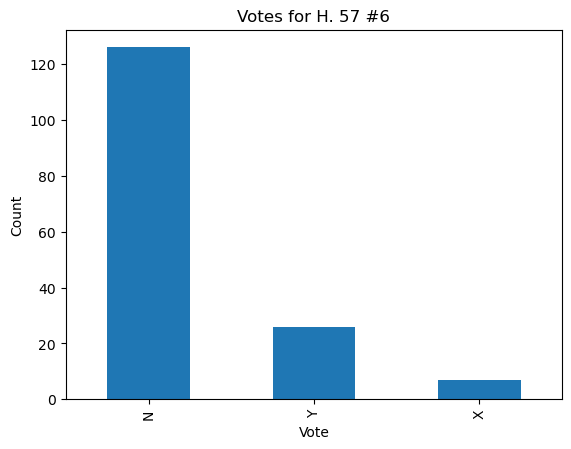

In [156]:
#plotting data for H 57 amendment 6
plot_votes(df_2025, "H. 57", "#6")


In [158]:
import requests
# pulling data for specific bill from Open States API, could be useful for integrating to the dashboard
API_KEY = "b70ea1c9-daf6-4f4a-83e0-59504cd0a080"
BASE_URL = "https://v3.openstates.org/bills"
bill_id = "H 57"  
jurisdiction = "Massachusetts"

headers = {"X-API-KEY": API_KEY}

params = {
    "jurisdiction": jurisdiction,
    "identifier": bill_id
}

response = requests.get(BASE_URL, params=params, headers=headers)
if response.status_code == 200:
    data = response.json()
    results = data.get("results", [])
    if results:
        bill = results[0]  # assuming identifier is unique
        print("Bill ID:", bill.get("identifier"))
        print("Chamber:", bill.get("from_organization", {}).get("name"))
        print("Title:", bill.get("title"))
        print("First Action:", bill.get("first_action_date"))
        print("Latest Action:", bill.get("latest_action_date"))
        print("Latest Description:", bill.get("latest_action_description"))
        print("Session:", bill.get("session"))
        print("Bill URL:", bill.get("openstates_url"))
    else:
        print("Bill not found")
else:
    print("Error:", response.status_code)

Bill ID: H 57
Chamber: House
Title: An Act making appropriations for fiscal year 2025 to provide for supplementing certain existing appropriations and for certain other activities and projects
First Action: 2025-02-06
Latest Action: 2025-02-06
Latest Description: Published as amended, see H58
Session: 194th
Bill URL: https://openstates.org/ma/bills/194th/H57/
